In [10]:
%pip install -q "qiskit==2.2.3" "qiskit-machine-learning==0.9.0" "qiskit-algorithms==0.4.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-machine-learning", "qiskit-algorithms", "torch", "numpy", "scipy"]:
    print(name, version(name))
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
print("설치 및 import 확인 완료")

Python: 3.13.16
qiskit 2.2.3
qiskit-machine-learning 0.9.0
qiskit-algorithms 0.4.0
torch 2.11.0+cpu
numpy 2.1.3
scipy 1.16.3
설치 및 import 확인 완료



최적화 완료
최적 파라미터: [1.14744501 3.14158855]
최소 손실: 7.116472313724154e-23

예측 결과: [0, 1, 1, 0]
실제 레이블: [0, 1, 1, 0]
정확도: 100.0%


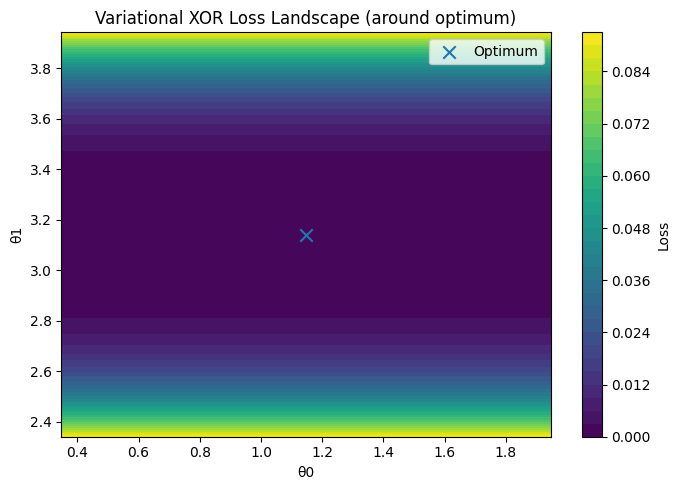


시각화 이미지 저장 완료: vqe_xor_loss_landscape.png

측정 기대값(⟨Z⟩): [-1.0, 1.0, 1.0, -1.0]


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.optimizers import COBYLA

# -----------------------------------------------------
# 1) 데이터(XOR)
# -----------------------------------------------------
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([0, 1, 1, 0])              # 라벨: 0/1
targets = 2*y - 1                       # 타깃: -1(0), +1(1)

# -----------------------------------------------------
# 2) 파라미터/회로
# -----------------------------------------------------
θ0, θ1 = Parameter("θ0"), Parameter("θ1")

def make_ansatz(x):
    qc = QuantumCircuit(2)
    qc.ry(np.pi * x[0], 0)
    qc.ry(np.pi * x[1], 1)
    qc.cx(0, 1)
    qc.ry(θ0, 0)
    qc.ry(θ1, 1)
    return qc

# 관측 연산자: Qiskit의 ZI는 1번 큐비트의 Z 기댓값
H = SparsePauliOp.from_list([("ZI", 1.0)])

# Estimator는 전역 1회 생성
estimator = StatevectorEstimator(default_precision=0.0, seed=42)

# -----------------------------------------------------
# 3) 손실 함수(평균제곱오차)
# -----------------------------------------------------
def loss_function(params):
    losses = []
    for i, x in enumerate(X):
        circuit = make_ansatz(x)
        value = float(estimator.run([(circuit, H, params)]).result()[0].data.evs)
        losses.append((value - targets[i])**2)
    return float(np.mean(losses))

# -----------------------------------------------------
# 4) 최적화(단 한 번 실행)
#    COBYLA 내부에서 maxiter만큼 반복
# -----------------------------------------------------
optimizer = COBYLA(maxiter=100)
x0 = [0.1, 0.1]
result = optimizer.minimize(loss_function, x0=x0)

print("\n최적화 완료")
print("최적 파라미터:", result.x)
print("최소 손실:", result.fun)

# -----------------------------------------------------
# 5) 예측 및 정확도
#    value>0 → 1, value<=0 → 0
# -----------------------------------------------------
preds = []
raw_values = []
for x in X:
    circuit = make_ansatz(x)
    v = float(estimator.run([(circuit, H, result.x)]).result()[0].data.evs)
    raw_values.append(v)
    preds.append(int(v > 0))

preds = np.array(preds)
raw_values = np.array(raw_values)

print("\n예측 결과:", preds.tolist())
print("실제 레이블:", y.tolist())
acc = (preds == y).mean()
print(f"정확도: {acc*100:.1f}%")

# -----------------------------------------------------
# 6) 손실 곡선 수집/시각화 (옵션)
#    학습 이력이 아니라 최적점 주변 각도를 격자로 평가합니다.
# -----------------------------------------------------
def sweep_loss(center, span=0.6, num=40):
    a = np.linspace(center[0]-span, center[0]+span, num)
    b = np.linspace(center[1]-span, center[1]+span, num)
    A, B = np.meshgrid(a, b)
    Z = np.zeros_like(A)
    for i in range(num):
        for j in range(num):
            Z[i, j] = loss_function([A[i, j], B[i, j]])
    return A, B, Z

A, B, Z = sweep_loss(result.x, span=0.8, num=25)

plt.figure(figsize=(7,5))
cs = plt.contourf(A, B, Z, levels=30)
plt.colorbar(cs, label="Loss")
plt.scatter([result.x[0]], [result.x[1]], marker="x", s=80, label="Optimum")
plt.title("Variational XOR Loss Landscape (around optimum)")
plt.xlabel("θ0"); plt.ylabel("θ1")
plt.legend()
plt.tight_layout()
plt.savefig("vqe_xor_loss_landscape.png", dpi=300)
plt.show()

print("\n시각화 이미지 저장 완료: vqe_xor_loss_landscape.png")

# 원시 기대값도 참고로 출력
print("\n측정 기대값(⟨Z⟩):", np.round(raw_values, 4).tolist())

assert np.isfinite(result.fun) and result.fun < 1e-4
assert np.array_equal(preds, y)
assert raw_values.shape == (4,)

Running Quantum XOR Classifier Optimization...

최적화 완료
최적 파라미터: [1.14744501 3.14158855]
최소 손실    : 0.00000000

Prediction Results Verification
예측 결과  : [0, 1, 1, 0]
실제 레이블: [0, 1, 1, 0]
테스트 정확도: 100.0%
측정 기대값(⟨Z⟩): [-1.0, 1.0, 1.0, -1.0]
검증 통과: 양자 모델이 XOR 문제를 완벽하게 학습했습니다.


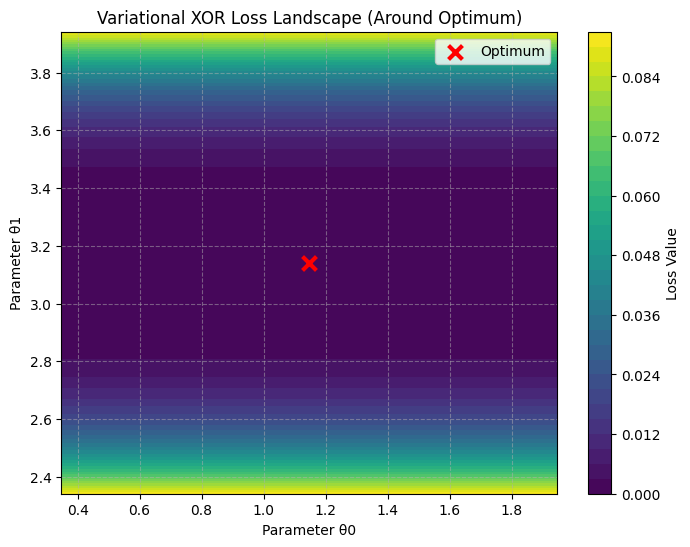

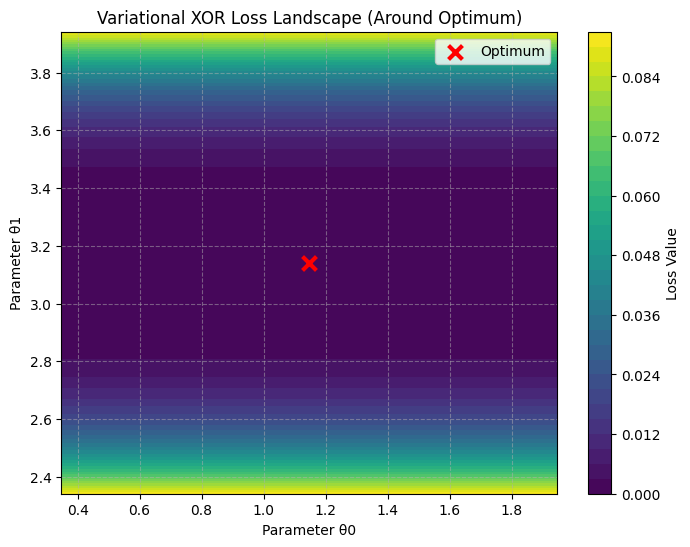


시각화 완료


In [14]:
# 코랩 환경에서 Matplotlib 그래프 출력 활성화
%matplotlib inline

# ==============================================================================
# STEP 1. 라이브러리 임포트 및 XOR 데이터 정의
# ==============================================================================
# 수치 연산, 시각화, Qiskit 회로, 파라미터, 파울리 연산자, Estimator 프리미티브,
# 그리고 COBYLA 고전 최적화기를 불러옵니다.
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.optimizers import COBYLA

# XOR 데이터셋 정의: 입력 X와 라벨 y (0 또는 1)
# 딥러닝/머신러닝에서 주로 사용하는 -1, +1 스케일의 타깃 값도 함께 정의합니다.
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])              # 라벨: 0 또는 1
targets = 2 * y - 1                     # 타깃: -1 (0일 때), +1 (1일 때)


# ==============================================================================
# STEP 2. 변분 양자 회로(Ansatz) 및 Estimator 설정
# ==============================================================================
# 학습 대상 파라미터 θ0, θ1 정의
θ0, θ1 = Parameter("θ0"), Parameter("θ1")

def make_ansatz(x):
    """입력 데이터 x[0], x[1]을 받아 2큐비트 양자 회로를 생성합니다."""
    qc = QuantumCircuit(2)
    qc.ry(np.pi * x[0], 0)
    qc.ry(np.pi * x[1], 1)
    qc.cx(0, 1)
    qc.ry(θ0, 0)
    qc.ry(θ1, 1)
    return qc

# 관측 연산자 설정: 1번 큐비트의 Z 기댓값을 측정하기 위한 연산자 ("ZI")
H = SparsePauliOp.from_list([("ZI", 1.0)])

# 전역 상태벡터 추정기(Estimator) 생성
estimator = StatevectorEstimator(default_precision=0.0, seed=42)


# ==============================================================================
# STEP 3. 손실 함수 (Mean Squared Error, 평균제곱오차) 구현
# ==============================================================================
def loss_function(params):
    """
    현재 파라미터 params와 4가지 XOR 입력 데이터를 조합하여
    전체 예측값과 타깃 간의 평균제곱오차(MSE Loss)를 계산합니다.
    """
    losses = []
    for i, x in enumerate(X):
        circuit = make_ansatz(x)
        value = float(estimator.run([(circuit, H, params)]).result()[0].data.evs)
        losses.append((value - targets[i]) ** 2)
    return float(np.mean(losses))


# ==============================================================================
# STEP 4. COBYLA 최적화기를 이용한 양자 모델 학습
# ==============================================================================
# 최대 반복 횟수(maxiter=100)를 가진 COBYLA 옵티마이저를 설정하고,
# 초기 파라미터 [0.1, 0.1]에서 시작하여 손실을 최소화하는 파라미터를 탐색합니다.
optimizer = COBYLA(maxiter=100)
x0 = [0.1, 0.1]

print("=" * 60)
print("Running Quantum XOR Classifier Optimization...")
print("=" * 60)

result = optimizer.minimize(loss_function, x0=x0)

print("\n최적화 완료")
print("최적 파라미터:", result.x)
print(f"최소 손실    : {result.fun:.8f}")


# ==============================================================================
# STEP 5. 예측 수행, 정확도 검증 및 결과 출력
# ==============================================================================
# 학습된 최적 파라미터를 이용해 4개 입력에 대한 예측값을 구하고,
# 기댓값이 0보다 크면 1, 아니면 0으로 분류합니다.
preds = []
raw_values = []
for x in X:
    circuit = make_ansatz(x)
    v = float(estimator.run([(circuit, H, result.x)]).result()[0].data.evs)
    raw_values.append(v)
    preds.append(int(v > 0))

preds = np.array(preds)
raw_values = np.array(raw_values)

print("\n" + "=" * 60)
print("Prediction Results Verification")
print("=" * 60)
print("예측 결과  :", preds.tolist())
print("실제 레이블:", y.tolist())
acc = (preds == y).mean()
print(f"테스트 정확도: {acc * 100:.1f}%")
print("측정 기대값(⟨Z⟩):", np.round(raw_values, 4).tolist())

# 엄격한 결과 검증 (Assertions)
assert np.isfinite(result.fun) and result.fun < 1e-4, "손실 값이 허용 범위를 초과했습니다!"
assert np.array_equal(preds, y), "XOR 분류 정확도가 100%가 아닙니다!"
assert raw_values.shape == (4,), "예측 결과 형태가 올바르지 않습니다!"
print("검증 통과: 양자 모델이 XOR 문제를 완벽하게 학습했습니다.")


# ==============================================================================
# STEP 6. 최적점 주변 Loss Landscape 시각화 (Contour Plot)
# ==============================================================================
# 최적 파라미터 주변의 공간을 격자로 탐색하여 Loss 지형을 2차원 컨투어 플롯으로 시각화합니다.
def sweep_loss(center, span=0.6, num=40):
    a = np.linspace(center[0] - span, center[0] + span, num)
    b = np.linspace(center[1] - span, center[1] + span, num)
    A, B = np.meshgrid(a, b)
    Z = np.zeros_like(A)
    for i in range(num):
        for j in range(num):
            Z[i, j] = loss_function([A[i, j], B[i, j]])
    return A, B, Z

A, B, Z = sweep_loss(result.x, span=0.8, num=25)

fig = plt.figure(figsize=(8, 6))

cs = plt.contourf(A, B, Z, levels=30, cmap="viridis")
plt.colorbar(cs, label="Loss Value")
plt.scatter([result.x[0]], [result.x[1]], marker="x", s=100, color="red", linewidth=3, label="Optimum")

plt.title("Variational XOR Loss Landscape (Around Optimum)")
plt.xlabel("Parameter θ0")
plt.ylabel("Parameter θ1")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

display(fig)
plt.show()

print("\n시각화 완료")